# Photosynthetic Choice Analysis
This notebook analyzes the results of the metabolic simulations to compare different photosynthetic modes (C3, C4, and intermediates). It generates visualizations for ATP turnover, light uptake, total flux, and biomass production, and predicts the optimal photosynthetic type based on anatomical and biochemical constraints.

## 1. Setup and Imports
Import necessary libraries for data manipulation and visualization, and load the metabolic model.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
import sys
from Auxiliary import *
from Flux import *
from Visualization import *
import numpy as np
import altair as alt
from cobra.io import read_sbml_model
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
pd.options.mode.chained_assignment = None  # default='warn'
import plotly
plotly.offline.init_notebook_mode(connected=True)

In [2]:
# Load the C4 metabolic model
c4_model = read_sbml_model("../Models/c4_model.xml")

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-20


## 2. Data Preparation
Load simulation results from CSV files, structure them for analysis, and calculate derived metrics like Quantum Yield.

### 2.1 C3 Scenario Data
Process data where C3 photosynthesis was enforced.

In [3]:
# Load raw C3 scan data
df_C3 = pd.read_csv("../Datasets/Scan_C3_Weighted.csv")

In [4]:
# Structure the data for analysis using helper function
structured_C3 = structure_data(df=df_C3, model=c4_model, filename="../Datasets/C3_Weighted_Structured.csv")

In [5]:
# Calculate Quantum Yield (Carbon Uptake / Total Light Uptake)
structured_C3["Quantum Yield"] = structured_C3["Carbon Uptake"] / (structured_C3["Light Mesophyll"] + structured_C3["Light Bundle Sheath"])

In [6]:
structured_C3

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Yield
0,50.0,1000,0.4,1000.0,20.0,20.0,3.7,714.285714,63.514286,1.0,...,7.714286,14.214286,0.0,0.0,2.142857,54.6,54.6,0.0,0.0,0.025714
1,55.0,1000,0.4,1000.0,20.0,20.0,3.7,607.142857,9.171429,1.0,...,0.071429,17.500000,0.0,0.0,0.000000,37.8,37.8,0.0,0.0,0.032451
2,60.0,1000,0.4,1000.0,20.0,20.0,3.7,506.500000,9.171429,1.0,...,0.071429,13.714286,0.0,0.0,0.000000,27.3,27.3,0.0,0.0,0.038784
3,65.0,1000,0.4,1000.0,20.0,20.0,3.7,437.428571,9.171429,1.0,...,0.071429,11.142857,0.0,0.0,0.000000,20.1,20.1,0.0,0.0,0.044783
4,70.0,1000,0.4,1000.0,20.0,20.0,3.7,387.214286,9.171429,1.0,...,0.071429,9.285714,0.0,0.0,0.000000,14.9,14.9,0.0,0.0,0.050456
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,80.0,1000,2.2,1000.0,20.0,20.0,3.7,312.500000,16.500000,1.0,...,0.000000,5.531250,0.0,0.0,1.306250,17.8,17.8,0.0,0.0,0.060790
205,85.0,1000,2.2,1000.0,20.0,20.0,3.7,296.062500,10.312500,1.0,...,0.000000,5.062500,0.0,0.0,0.687500,12.6,12.6,0.0,0.0,0.065279
206,90.0,1000,2.2,1000.0,20.0,20.0,3.7,281.750000,4.606250,1.0,...,0.000000,4.562500,0.0,0.0,0.206250,7.9,7.9,0.0,0.0,0.069843
207,95.0,1000,2.2,1000.0,20.0,20.0,3.7,263.593750,5.156250,1.0,...,0.000000,3.843750,0.0,0.0,0.206250,3.6,3.6,0.0,0.0,0.074419


In [7]:
# Select a specific subset of data for standard conditions
selected_C3 = select_data(prepared_df=structured_C3, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

In [8]:
selected_C3

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Yield
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,349.214286,9.171429,1.0,...,0.071429,7.857143,0.0,0.0,0.000000,10.9,10.9,0.0,0.0,0.055806
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,349.000000,9.466667,1.0,...,0.000000,7.933333,0.0,0.0,0.000000,11.7,11.7,0.0,0.0,0.055793
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,348.750000,9.712500,1.0,...,0.000000,7.937500,0.0,0.0,0.000000,12.5,12.5,0.0,0.0,0.055794
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,348.529412,9.923529,1.0,...,0.000000,7.941176,0.0,0.0,0.000000,13.3,13.3,0.0,0.0,0.055795
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,348.388889,10.133333,1.0,...,0.000000,7.944444,0.0,0.0,0.000000,14.1,14.1,0.0,0.0,0.055785
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,348.210526,10.278947,1.0,...,0.000000,7.947368,0.0,0.0,0.000000,14.8,14.8,0.0,0.0,0.055790
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,348.100000,10.450000,1.0,...,0.000000,7.950000,0.0,0.0,0.000000,15.6,15.6,0.0,0.0,0.055780
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,347.952381,10.580952,1.0,...,0.095238,7.857143,0.0,0.0,0.000000,16.4,16.4,0.0,0.0,0.055783
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,346.818182,11.727273,1.0,...,0.000000,7.954545,0.0,0.0,0.000000,17.2,17.2,0.0,0.0,0.055781
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,346.739130,11.869565,1.0,...,0.000000,7.956522,0.0,0.0,0.000000,18.0,18.0,0.0,0.0,0.055771


### 2.2 Variable Scenario Data (Free Choice)
Process data where the model could choose between C3 and C4 pathways ("Variable").

In [9]:
# Load raw Variable scan data
df_C4 = pd.read_csv("../Datasets/Scan_Variable_Weighted.csv")

In [10]:
# Structure data and calculate Quantum Yield
structured_C4 = structure_data(df=df_C4, model = c4_model, filename="../Datasets/Variable_Weighted_Structured.csv")
structured_C4["Quantum Yield"] = structured_C4["Carbon Uptake"] / (structured_C4["Light Mesophyll"] + structured_C4["Light Bundle Sheath"])

In [11]:
# Select subset for standard conditions
selected_C4 = select_data(prepared_df=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Yield
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,333.642857,19.857143,1.0,...,0.0,7.642857,0.0,0.0,0.000000,10.5,10.5,0.0,0.0,0.056577
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,325.466667,25.766667,1.0,...,0.0,7.466667,0.0,0.0,0.000000,11.0,11.0,0.0,0.0,0.056942
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,323.375000,27.150000,1.0,...,0.0,7.437500,0.0,0.0,0.000000,11.6,11.6,0.0,0.0,0.057057
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,320.235294,29.235294,1.0,...,0.0,7.352941,0.0,0.0,0.000000,12.2,12.2,0.0,0.0,0.057229
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,320.055556,29.422222,1.0,...,0.0,7.388889,0.0,0.0,0.000000,12.9,12.9,0.0,0.0,0.057228
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,319.421053,29.936842,1.0,...,0.0,7.315789,0.0,0.0,0.000000,13.7,13.7,0.0,0.0,0.057248
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,319.200000,30.100000,1.0,...,0.0,7.300000,0.0,0.0,0.000000,14.4,14.4,0.0,0.0,0.057257
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,317.571429,31.638095,1.0,...,0.0,7.190476,0.0,0.0,0.157143,15.1,15.1,0.0,0.0,0.057272
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,313.000000,34.363636,1.0,...,0.0,7.000000,0.0,0.0,0.272727,15.4,15.4,0.0,0.0,0.057577
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,304.521739,40.752174,1.0,...,0.0,6.478261,0.0,0.0,0.734783,15.7,15.7,0.0,0.0,0.057925


### 2.3 C4-Only Scenario Data
Process data where C4 photosynthesis was enforced.

In [12]:
# Load raw C4-only scan data
df_C4_only = pd.read_csv("../Datasets/Scan_C4_Weighted.csv")

# Structure data
structured_C4_only = structure_data(df=df_C4_only, model = c4_model, filename="../Datasets/C4_Weighted_Structured.csv")

# Calculate Quantum Yield
structured_C4_only["Quantum Yield"] = structured_C4_only["Carbon Uptake"] / (structured_C4_only["Light Mesophyll"] + structured_C4_only["Light Bundle Sheath"])

In [13]:
# Select subset for standard conditions
selected_C4_only = select_data(prepared_df=structured_C4_only, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4_only

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Yield
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,145.857143,192.257143,1.0,...,0.0,3.571429,0.0,0.0,0.485714,0.0,0.0,0.0,0.0,0.059152
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,145.533333,189.000000,1.0,...,0.0,3.533333,0.0,0.0,0.500000,0.0,0.0,0.0,0.0,0.059785
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,130.187500,190.050000,1.0,...,0.0,3.562500,0.0,0.0,0.487500,0.0,0.0,0.0,0.0,0.062454
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,130.000000,190.194118,1.0,...,0.0,3.529412,0.0,0.0,0.494118,0.0,0.0,0.0,0.0,0.062462
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,123.111111,192.311111,1.0,...,0.0,3.555556,0.0,0.0,0.488889,0.0,0.0,0.0,0.0,0.063407
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,123.526316,190.421053,1.0,...,0.0,3.526316,0.0,0.0,0.473684,0.0,0.0,0.0,0.0,0.063705
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,122.900000,189.550000,1.0,...,0.0,3.550000,0.0,0.0,0.500000,0.0,0.0,0.0,0.0,0.064010
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,120.380952,185.166667,1.0,...,0.0,3.523810,0.0,0.0,0.471429,0.0,0.0,0.0,0.0,0.065456
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,120.500000,184.800000,1.0,...,0.0,3.545455,0.0,0.0,0.490909,0.0,0.0,0.0,0.0,0.065509
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,111.695652,183.865217,1.0,...,0.0,3.521739,0.0,0.0,0.508696,0.0,0.0,0.0,0.0,0.067668


## 3. Comparative Analysis: Enforced C3 vs. Free Choice
Compare metabolic costs and outputs between the enforced C3 scenario and the scenario where the model optimizes for the best pathway (often resulting in C4 or intermediates).

- Visualize the ATP maintenance costs associated with different photosynthetic modes.
- Visualize the total photon uptake required.
- Visualize the total metabolic flux (proxy for enzyme investment/cost).

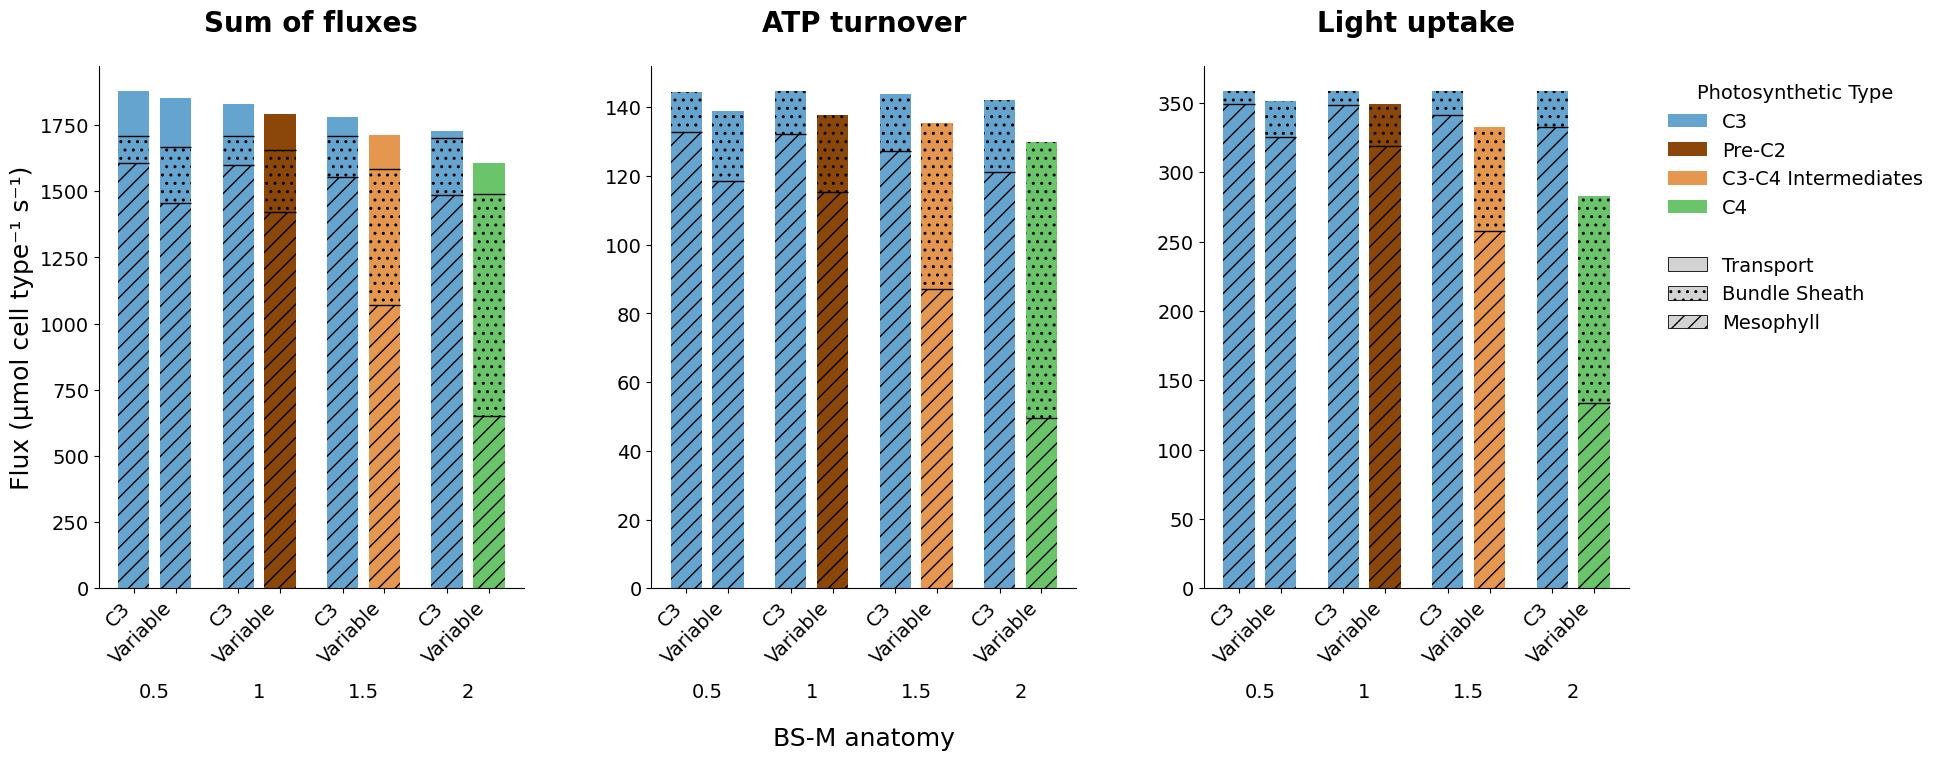

In [14]:
# Subplots, Bundle Sheath and Mesophyll comparison
metabolic_comparison_subplots(df_C3=structured_C3, df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

### 3.1 Biomass Production
Visualize the biomass production rate.

In [15]:
# Compare Biomass Production
comparison_Biomass_barplots_3D(df_C3=structured_C3, df_C4=structured_C4, df_C4_only=structured_C4_only,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

alt.FacetChart(...)

### 3.2 Nitrogen assimilation


In [16]:
def nitrogen_comparison_subplots(df_C3, df_C4, PPFD, Vc_Vo, CO2, PC_BS, NH3):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), sharey=False)
    volume_ratios = [0.5, 1, 1.5, 2]
    color_map = {'C3': '#64a4ceff', 'C3_C4_Type_I': '#e6954cfb', 'C4': '#69c569fe', 'Unidentified': '#884405fb'}
    
    def get_data():
        s_C3 = select_data(prepared_df=df_C3, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        s_C4 = select_data(prepared_df=df_C4, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        s_C3 = s_C3[s_C3.V_BS_M.isin(volume_ratios)].copy()
        s_C4 = s_C4[s_C4.V_BS_M.isin(volume_ratios)].copy()
        s_C3['Classification'] = "C3"
        s_C4['Classification'] = "Variable"
        return pd.concat([s_C3, s_C4])

    df_combined = get_data()

    # Summing GS compartments for Mesophyll (M) and Bundle Sheath (BS)
    df_combined['GS_Total_M'] = df_combined[["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]].sum(axis=1)
    df_combined['GS_Total_B'] = df_combined[["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]].sum(axis=1)

    plot_configs = [
        (ax1, "Nitrate Reductase (NR)", "Nitrate_reductase_M", "Nitrate_reductase_B"),
        (ax2, "Glutamine Synthetase (GS)", "GS_Total_M", "GS_Total_B")
    ]

    for ax, title, col_meso, col_bs in plot_configs:
        tick_positions = []
        tick_labels = []
        bar_width = 0.22
        group_gap = 0.06

        for i, vol in enumerate(volume_ratios):
            vol_data = df_combined[df_combined['V_BS_M'] == vol]
            for j, cls in enumerate(["C3", "Variable"]):
                row = vol_data[vol_data['Classification'] == cls]
                if row.empty: continue
                
                base_color = color_map.get(row['Photosynthesis'].iloc[0], 'black')
                pos = i + (j * (bar_width + group_gap))
                tick_positions.append(pos)
                tick_labels.append(cls)

                v_m = row[col_meso].iloc[0]
                v_b = row[col_bs].iloc[0]

                # Stacked bars
                ax.bar(pos, v_m, width=bar_width, color=base_color, hatch='//', edgecolor='white', label='Mesophyll' if i==0 and j==0 else "")
                ax.bar(pos, v_b, bottom=v_m, width=bar_width, color=base_color, edgecolor='white', label='Bundle Sheath' if i==0 and j==0 else "")

        ax.set_title(title, fontsize=14, fontweight='bold', pad=25)
        ax.set_ylabel("Flux (µmol cell type⁻¹ s⁻¹)", fontsize=11, fontweight='bold')
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)

        for i, vol in enumerate(volume_ratios):
            group_center = i + (bar_width + group_gap) / 2
            ax.text(group_center, -0.12, f"V={vol}", transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=10, fontweight='bold')

    # Legend
    fill_elements = [
        Patch(facecolor='darkgray', edgecolor='black', label='Bundle Sheath'),
        Patch(facecolor='darkgray', edgecolor='black', hatch='//', label='Mesophyll')
    ]
    photo_elements = [Patch(facecolor=c, edgecolor='black', label=l) for l, c in color_map.items()]
    
    ax2.legend(handles=photo_elements + [Patch(alpha=0, label="")] + fill_elements, 
               title="Photosynthetic Type / Compartment", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25, wspace=0.3, right=0.8)
    plt.show()

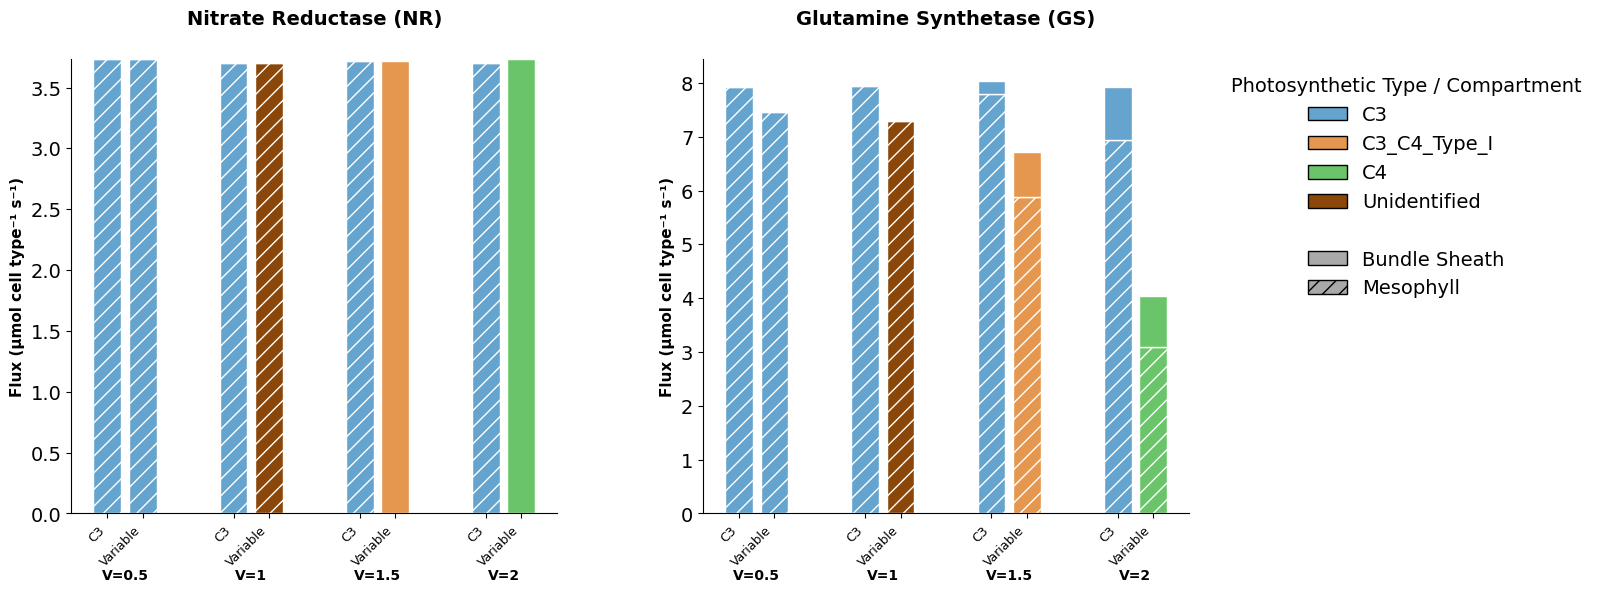

In [17]:
nitrogen_comparison_subplots(df_C3=structured_C3, df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

In [18]:
def nitrogen_linear_plot(df_C4, PPFD, Vc_Vo, CO2, PC_BS, NH3):

    s_C4 = select_data(prepared_df=df_C4, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
    
    volume_ratios = [0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2]
    df_plot = s_C4[s_C4.V_BS_M.isin(volume_ratios)].sort_values('V_BS_M').copy()

    # Totals
    df_plot['GS_Total_M'] = df_plot[["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]].sum(axis=1)
    df_plot['GS_Total_B'] = df_plot[["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]].sum(axis=1)
    df_plot['NR_Total'] = df_plot["Nitrate_reductase_M"] + df_plot["Nitrate_reductase_B"]
    df_plot['GS_Total'] = df_plot['GS_Total_M'] + df_plot['GS_Total_B']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    c_meso = '#2ecc71' 
    c_bs = '#3498db'   
    c_total = 'black'

    # Nitrate Reductase (NR)
    ax1.plot(df_plot['V_BS_M'], df_plot['Nitrate_reductase_M'], label='Mesophyll', marker='o', color=c_meso, linestyle='--')
    ax1.plot(df_plot['V_BS_M'], df_plot['Nitrate_reductase_B'], label='Bundle Sheath', marker='o', color=c_bs, linestyle='--')
    ax1.plot(df_plot['V_BS_M'], df_plot['NR_Total'], label='Total NR', marker='s', color=c_total, linewidth=2)
    ax1.set_title("Nitrate Reductase (NR) Flux", fontweight='bold')

    # Glutamine Synthetase (GS)
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total_M'], label='Mesophyll', marker='o', color=c_meso, linestyle='--')
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total_B'], label='Bundle Sheath', marker='o', color=c_bs, linestyle='--')
    ax2.plot(df_plot['V_BS_M'], df_plot['GS_Total'], label='Total GS', marker='s', color=c_total, linewidth=2)
    ax2.set_title("Glutamine Synthetase (GS) Flux", fontweight='bold')

    for ax in [ax1, ax2]:
        ax.set_xlabel("BS-M anatomy", fontsize=10)
        ax.set_ylabel("Flux (µmol cell type⁻¹ s⁻¹)", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(frameon=False)
        ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

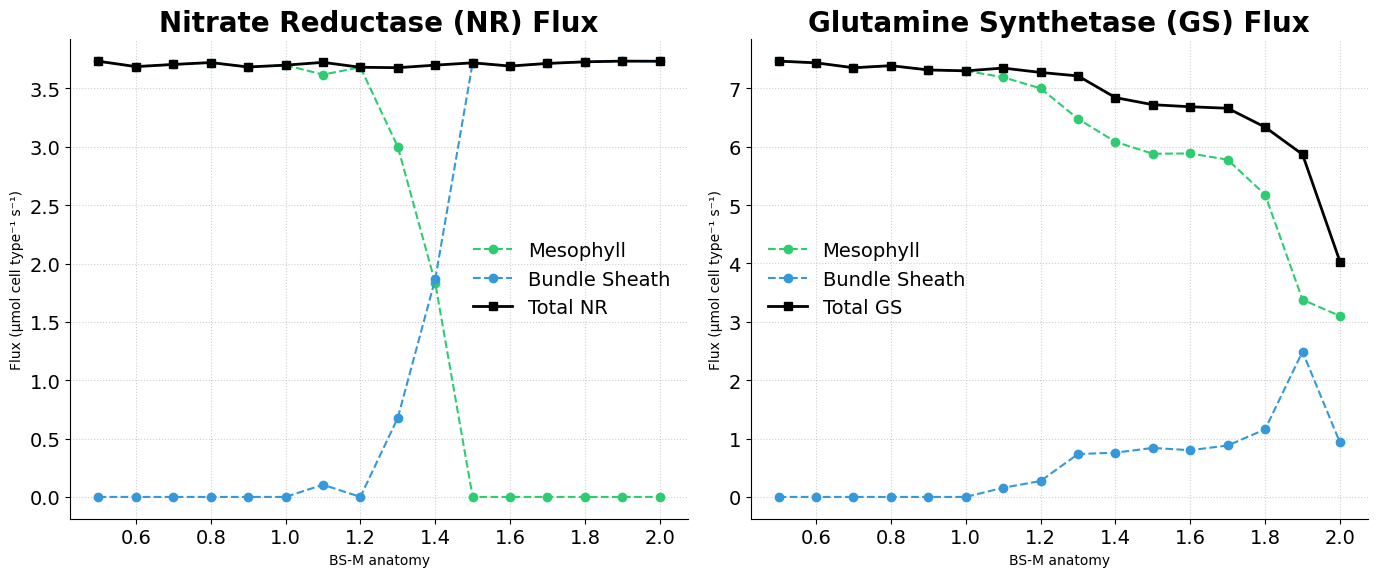

In [19]:
nitrogen_linear_plot(df_C4=structured_C4,PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

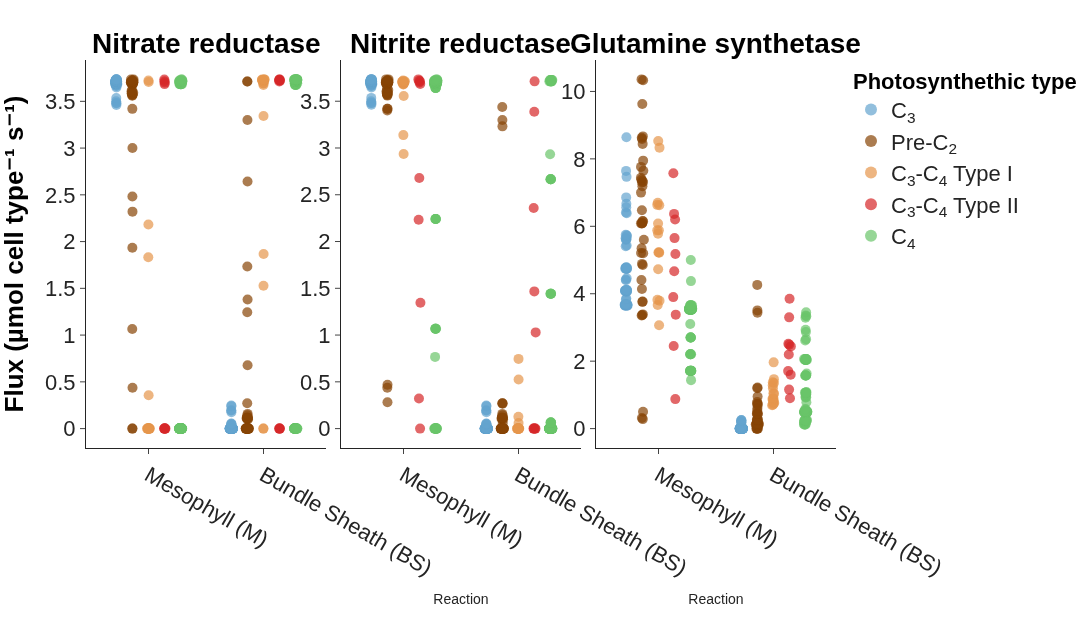

In [20]:
import plotly.express as px
import pandas as pd

# -------------------- NITRATE --------------------
df1 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['Nitrate_reductase_M', 'Nitrate_reductase_B'],
    var_name='Reaction',
    value_name='Flux'
)

df1['Reaction'] = df1['Reaction'].replace({
    'Nitrate_reductase_M': 'Mesophyll (M)',
    'Nitrate_reductase_B': 'Bundle Sheath (BS)'
})

df1["Process"] = "Nitrate Reductase"

# -------------------- NITRITE --------------------
df2 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['Nitrite_reductase_M', 'Nitrite_reductase_B'],
    var_name='Reaction',
    value_name='Flux'
)

df2['Reaction'] = df2['Reaction'].replace({
    'Nitrite_reductase_M': 'Mesophyll (M)',
    'Nitrite_reductase_B': 'Bundle Sheath (BS)'
})

df2["Process"] = "Nitrite Reductase"

# -------------------- GLUTAMINE --------------------
structured_C4['GS_Total_M'] = structured_C4[
    ["Glutamine_syn_c_M", "Glutamine_syn_m_M", "Glutamine_syn_p_M"]
].sum(axis=1)

structured_C4['GS_Total_B'] = structured_C4[
    ["Glutamine_syn_c_B", "Glutamine_syn_m_B", "Glutamine_syn_p_B"]
].sum(axis=1)

df3 = structured_C4.melt(
    id_vars=['Photosynthesis'],
    value_vars=['GS_Total_M', 'GS_Total_B'],
    var_name='Reaction',
    value_name='Flux'
)

df3['Reaction'] = df3['Reaction'].replace({
    'GS_Total_M': 'Mesophyll (M)',
    'GS_Total_B': 'Bundle Sheath (BS)'
})

df3["Process"] = "Glutamine (GS Total)"

df_all = pd.concat([df1, df2, df3], ignore_index=True)

# -------------------- 
photosynthesis_map = {
    'C3': 'C<sub>3</sub>',
    'Unidentified': 'Pre-C<sub>2</sub>',
    'C3_C4_Type_I': 'C<sub>3</sub>-C<sub>4</sub> Type I',
    'C3_C4_Type_II': 'C<sub>3</sub>-C<sub>4</sub> Type II',
    'C4': 'C<sub>4</sub>'
}

df_all['Photosynthesis'] = df_all['Photosynthesis'].map(photosynthesis_map)

custom_colors = {
    'C<sub>3</sub>': '#64a4ce', 
    'Pre-C<sub>2</sub>': '#884405',
    'C<sub>3</sub>-C<sub>4</sub> Type I': '#e6954c', 
    'C<sub>3</sub>-C<sub>4</sub> Type II': '#d62728',
    'C<sub>4</sub>': '#69c569'
}

fig = px.strip(
    df_all,
    x="Reaction",
    y="Flux",
    color="Photosynthesis",
    facet_col="Process",  
    stripmode="group",
    color_discrete_map=custom_colors,
    category_orders={
        "Photosynthesis": [
            'C<sub>3</sub>', 
            'Pre-C<sub>2</sub>', 
            'C<sub>3</sub>-C<sub>4</sub> Type I', 
            'C<sub>3</sub>-C<sub>4</sub> Type II', 
            'C<sub>4</sub>'
        ],
        "Reaction": ["Mesophyll (M)", "Bundle Sheath (BS)"],
        "Process": ["Nitrate Reductase", "Nitrite Reductase", "Glutamine (GS Total)"]
    },
    template="simple_white"
)

fig.update_traces(marker=dict(size=10, opacity=0.7))

fig.update_layout(
    width=1600,
    height=600,
    xaxis_title="",
    yaxis_title="<b>Flux (µmol cell type⁻¹ s⁻¹)</b>",
    legend_title=dict(text="<b>Photosynthethic type</b>", font=dict(size=22, color="black")),
    legend=dict(
        font=dict(size=22),
        itemsizing='constant',  
        itemwidth=30            
    )
)

fig.update_xaxes(
    tickfont=dict(size=22)
)

fig.update_yaxes(
    matches=None, 
    showticklabels=True,
    tickfont=dict(size=22),
    title_font=dict(size=26, color="black")
)

name_map = {
    "Nitrate Reductase": "Nitrate reductase",
    "Nitrite Reductase": "Nitrite reductase",
    "Glutamine (GS Total)": "Glutamine synthetase"
}

fig.for_each_annotation(lambda a: a.update(
    text=f"<b>{name_map.get(a.text.split('=')[-1], a.text)}</b>",
    font=dict(size=28, color="black")   
))

fig.write_image("../Images/N_plots.svg", width=1600, height=600)

fig.show()

## 4. Reaction Flux Analysis
Analyze how specific reaction fluxes change with anatomical parameters ($V_{BS/M}$) and photorespiratory conditions ($V_c/V_o$).

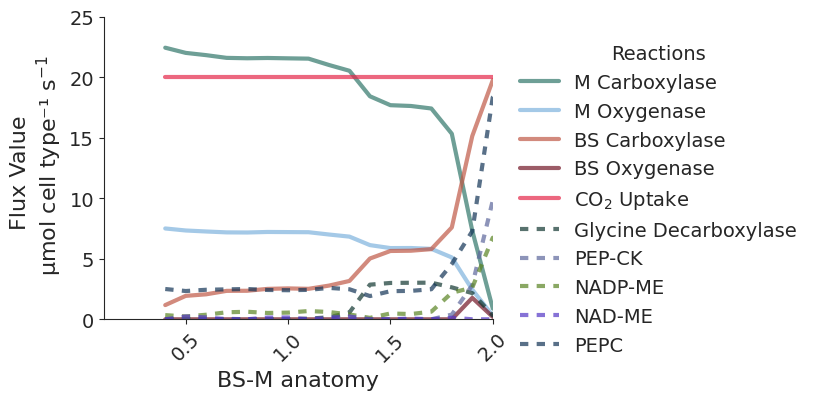

In [21]:
# Line plot of key reactions vs Volume Ratio
g = reaction_lineplot_VRatio(data=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

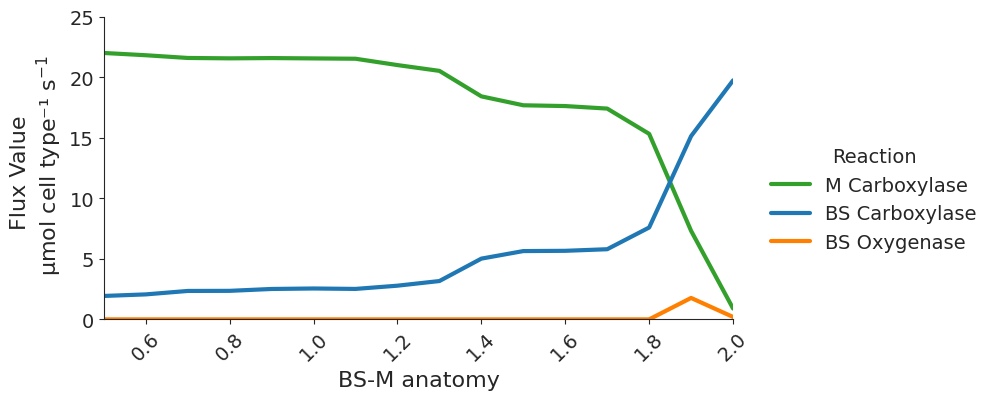

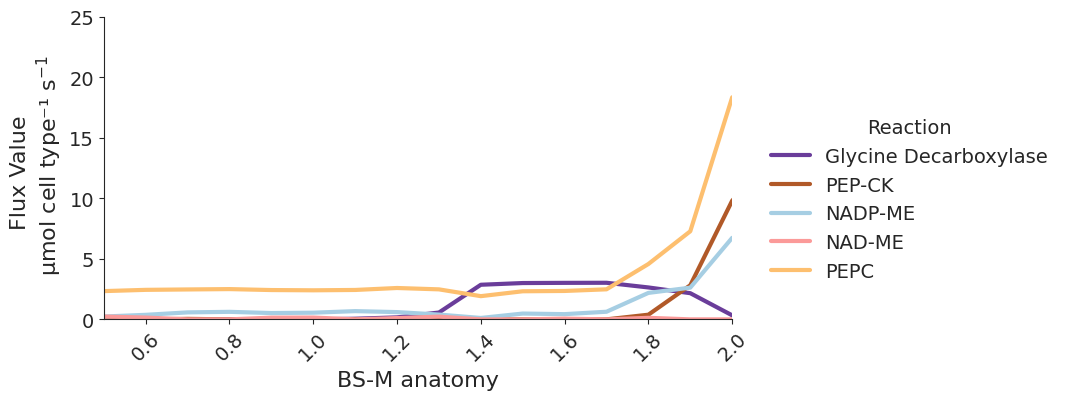

In [22]:
# Split line plot of key reactions vs Volume Ratio
g1, g2 = reaction_lineplot_VRatio_split(data=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)

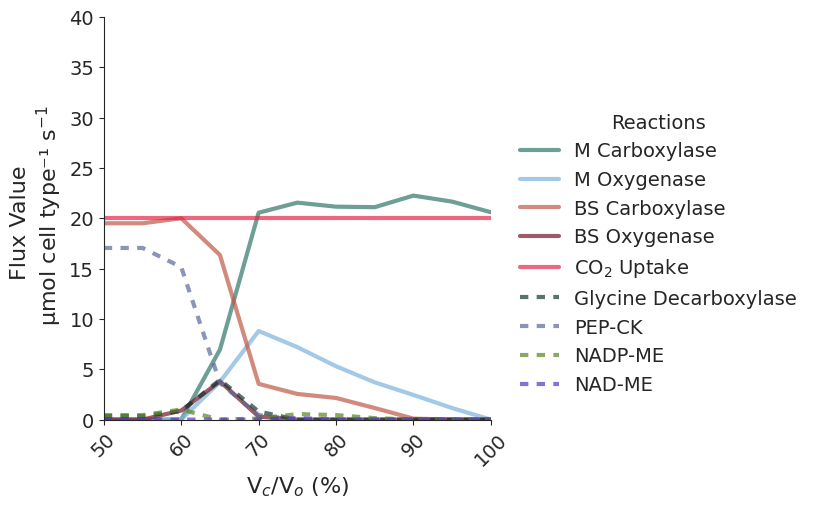

In [23]:
# Line plot of key reactions vs Vc/Vo ratio
reaction_lineplot_Vc_Vo(data=structured_C4, PPFD=1000, V_BS_M = 1 ,CO2=20, PC_BS=1, NH3 = 1000)

## 5. Photosynthetic Type Prediction (Bubble Plots)
Generate bubble plots to visualize the distribution of Rubisco activity between Mesophyll and Bundle Sheath cells, effectively predicting the photosynthetic type (C3, C3-C4, C4) across the parameter space of anatomy ($V_{BS/M}$) and photorespiration ($V_c/V_o$).

In [24]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_flux_solutions_bubbles_V1(
    structured_C4,
    PPFD=1000,
    CO2=20,
    PC_BS=1,
    NH3=1000,
    desired_max_marker_px=18,
    output_svg="../Images/Bubble_complete.svg",
    use_jitter=False,
):
  """Generates a bubble plot using a single trace per facet to guarantee strict

  global size-based z-ordering across both colors.
  """

  data = select_data_3D(
      prepared_df=structured_C4, PPFD=PPFD, CO2=CO2, PC_BS=PC_BS, NH3=NH3
  )

  # Filter out V_BS_M < 0.2
  data = data[data["V_BS_M"] >= 0.2].copy()

  VM_list = [1 / (1 + v) for v in data.V_BS_M]
  VBS_list = [v / (1 + v) for v in data.V_BS_M]
  data["BS_Carboxylation"] = data["BS_Rubisco"] + data["BS_Rubisco_C4"]
  data["M_Carboxylation"] = data["M_Rubisco"]

  for n in range(len(data)):
    data["M_Rubisco"].iloc[n] = data["M_Rubisco"].iloc[n] * VM_list[n]
    data["BS_Rubisco"].iloc[n] = data["BS_Rubisco"].iloc[n] * VBS_list[n]
    data["BS_Rubisco_C4"].iloc[n] = data["BS_Rubisco_C4"].iloc[n] * VBS_list[n]
    data["Glycine Decarboxylase"].iloc[n] = (
        data["Glycine Decarboxylase"].iloc[n] * VBS_list[n]
    )
    data["PEP-CK"].iloc[n] = data["PEP-CK"].iloc[n] * VBS_list[n]
    data["NADP-ME"].iloc[n] = data["NADP-ME"].iloc[n] * VBS_list[n]
    data["NAD-ME"].iloc[n] = data["NAD-ME"].iloc[n] * VBS_list[n]
    data["BS_Carboxylation"].iloc[n] = (
        data["BS_Carboxylation"].iloc[n] * VBS_list[n]
    )
    data["M_Carboxylation"].iloc[n] = data["M_Carboxylation"].iloc[n] * VM_list[n]

  df = pd.DataFrame(data)
  photo_intermediates = ["C3", "C3_C4_Type_I", "C3_C4_Type_II", "Unidentified", "C4"]
  df_filtered = df.loc[df["Photosynthesis"].isin(photo_intermediates)]

  df_melted = df_filtered.melt(
      id_vars=["Vc_Vo", "V_BS_M", "Photosynthesis"],
      value_vars=["M_Carboxylation", "BS_Carboxylation"],
      var_name="Enzyme",
      value_name="Z",
  )

  df_melted = df_melted.rename(columns={"Z": "Flux Values"})
  df_melted["Enzyme"] = df_melted.Enzyme.replace({
      "M_Carboxylation": "Mesophyll Carboxylation",
      "BS_Carboxylation": "Bundle Sheath Carboxylation",
  })
  df_melted["Photosynthesis"] = df_melted.Photosynthesis.replace({
      "C3_C4_Type_II": "C3-C4 Type II",
      "C3_C4_Type_I": "C3-C4 Type I",
  })
  df_melted["Photosynthesis"] = df_melted.Photosynthesis.replace({
      "C3-C4 Type I": "C3-C4",
      "C3-C4 Type II": "C3-C4",
  })
  df_melted["Photosynthesis"] = pd.Categorical(
      df_melted["Photosynthesis"],
      categories=["C3", "Unidentified", "C3-C4", "C4"],
      ordered=True,
  )

  if use_jitter:
    np.random.seed(0)
    jitter_mag = 0.01
    df_melted["V_BS_M_display"] = df_melted["V_BS_M"] + np.random.uniform(
        -jitter_mag, jitter_mag, size=len(df_melted)
    )
    x_col = "V_BS_M_display"
  else:
    x_col = "V_BS_M"

  # --- ORDEN GLOBAL POR TAMAÑO DESCENDENTE ---
  # Las más grandes primero (al fondo), las más pequeñas al final (al frente)
  df_melted = df_melted.sort_values(
      by=["Photosynthesis", "Flux Values"], ascending=[True, False]
  )

  enzyme_colors = {
      "Mesophyll Carboxylation": "#06402B",
      "Bundle Sheath Carboxylation": "#e6b705",
  }

  max_val = df_melted["Flux Values"].abs().max() if len(df_melted) > 0 else 1.0
  desired_px = desired_max_marker_px
  sizeref = 3.0 * max_val / (desired_px**2 + 1e-12)

  facets = ["C3", "Unidentified", "C3-C4", "C4"]
  fig = make_subplots(
      rows=1,
      cols=len(facets),
      shared_yaxes=True,
      horizontal_spacing=0.01,
      subplot_titles=[
          "<b>C<sub>3</sub></b>",
          "<b>Pre-C<sub>2</sub></b>",
          "<b>C<sub>3</sub>-C<sub>4</sub></b>",
          "<b>C<sub>4</sub></b>",
      ],
  )

  # 1. Agregar trazas invisibles al inicio solo para conservar la leyenda correctamente
  fig.add_trace(
      go.Scatter(
          x=[None],
          y=[None],
          mode="markers",
          marker=dict(size=10, color=enzyme_colors["Bundle Sheath Carboxylation"]),
          name="Bundle Sheath Carboxylation",
      ),
      row=1,
      col=1,
  )
  fig.add_trace(
      go.Scatter(
          x=[None],
          y=[None],
          mode="markers",
          marker=dict(size=10, color=enzyme_colors["Mesophyll Carboxylation"]),
          name="Mesophyll Carboxylation",
      ),
      row=1,
      col=1,
  )

  # 2. Recorrer cada facet y agregar UNA SOLA traza con el orden estricto de tamaño
  for i, facet_val in enumerate(facets, start=1):
    facet_data = df_melted[df_melted["Photosynthesis"] == facet_val]
    colors_list = [enzyme_colors[e] for e in facet_data["Enzyme"]]

    fig.add_trace(
        go.Scatter(
            x=facet_data[x_col],
            y=facet_data["Vc_Vo"],
            mode="markers",
            showlegend=False,  # Ocultamos para usar la leyenda principal de arriba
            marker=dict(
                size=facet_data["Flux Values"],
                sizemode="area",
                sizeref=sizeref,
                color=colors_list,
                line=dict(width=0, color="black"),
            ),
        ),
        row=1,
        col=i,
    )

  # --- LAYOUT Y ESTILOS ---
  fig.update_layout(
      height=420,
      width=1600,
      plot_bgcolor="white",
      font=dict(size=14, family="Arial"),
      margin=dict(l=70, r=180, t=50, b=80),
      legend=dict(
          orientation="v",
          yanchor="middle",
          y=0.5,
          x=1.02,
          xanchor="left",
          font=dict(size=14, family="Arial"),
      ),
      yaxis_title="<b>Rubisco carboxylation (%)</b>",
  )

  fig.update_xaxes(
      range=[0.35, 2.25],
      tickvals=np.arange(0.2, 2.21, 0.4),
      ticktext=[f"{v:.1f}" for v in np.arange(0.2, 2.01, 0.4)],
      tickangle=-45,
      tickformat=".1f",
      mirror=True,
      ticks="outside",
      showline=True,
      linecolor="black",
      gridcolor="#e8e8e8",
      griddash="dash",
      title_text="<b>BS-M anatomy</b>",
  )

  fig.update_yaxes(
      mirror=True,
      ticks="outside",
      showline=True,
      linecolor="black",
      gridcolor="#e8e8e8",
      griddash="dash",
      autorange="reversed",
      title_font=dict(size=15, family="Arial"),
  )

  for col in range(1, len(facets) + 1):
    fig.add_hline(
        y=75,
        line_dash="solid",
        line_color="red",
        line_width=2,
        opacity=0.35,
        layer="below",
        row=1,
        col=col,
    )

  # Regiones de fondo
  fig.add_shape(
      type="rect",
      x0=0.5,
      x1=1.1,
      y0=0,
      y1=1,
      xref="x1",
      yref="paper",
      fillcolor="rgba(100, 164, 206, 50)",
      opacity=0.5,
      layer="below",
      line_width=0,
  )
  fig.add_shape(
      type="rect",
      x0=0.7,
      x1=1.7,
      y0=0,
      y1=1,
      xref="x3",
      yref="paper",
      fillcolor="rgba(230, 149, 77, 50)",
      opacity=0.5,
      layer="below",
      line_width=0,
  )
  fig.add_shape(
      type="rect",
      x0=1.2,
      x1=2.2,
      y0=0,
      y1=1,
      xref="x4",
      yref="paper",
      fillcolor="rgba(107, 197, 107, 50)",
      opacity=0.5,
      layer="below",
      line_width=0,
  )

  fig.write_image(output_svg, width=1400, height=420)
  return fig

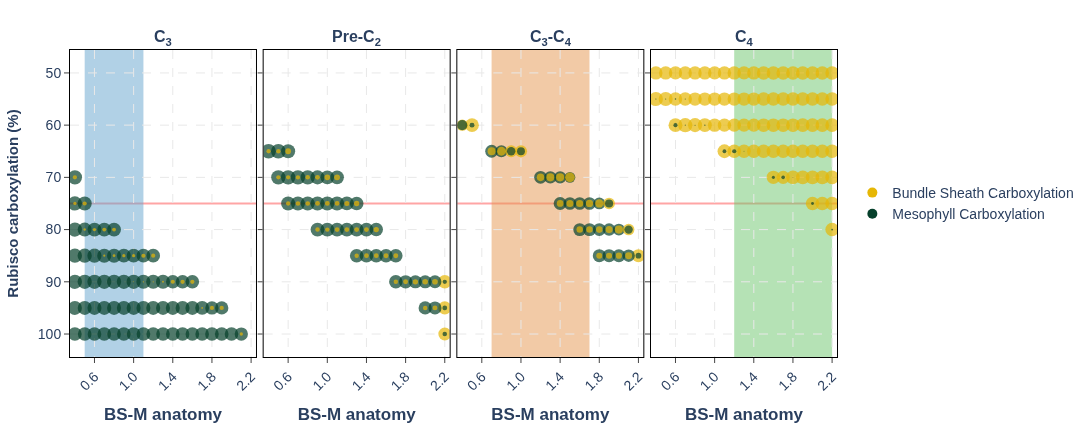

In [25]:
# Generate the bubble plot
plot_flux_solutions_bubbles_V1(structured_C4, CO2=20, PC_BS=1, NH3=1000)

In [26]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go


def plot_flux_solutions_bubbles_single_box(
    structured_C4,
    PPFD=1000,
    CO2=20,
    PC_BS=1,
    NH3=1000,
    desired_max_marker_px=18,
    output_svg="../Images/Bubble_Unsuberised_Single.svg",
    use_jitter=False,
):
    """Generates a single-panel bubble plot combining all data points without

    classification facets, maintaining strict global size-based z-ordering.
    """

    data = select_data_3D(
        prepared_df=structured_C4, PPFD=PPFD, CO2=CO2, PC_BS=PC_BS, NH3=NH3
    )

    # Filter out V_BS_M < 0.2
    data = data[data["V_BS_M"] >= 0.2].copy()

    VM_list = [1 / (1 + v) for v in data.V_BS_M]
    VBS_list = [v / (1 + v) for v in data.V_BS_M]
    data["BS_Carboxylation"] = data["BS_Rubisco"] + data["BS_Rubisco_C4"]
    data["M_Carboxylation"] = data["M_Rubisco"]

    for n in range(len(data)):
        data["M_Rubisco"].iloc[n] = data["M_Rubisco"].iloc[n] * VM_list[n]
        data["BS_Rubisco"].iloc[n] = data["BS_Rubisco"].iloc[n] * VBS_list[n]
        data["BS_Rubisco_C4"].iloc[n] = (
            data["BS_Rubisco_C4"].iloc[n] * VBS_list[n]
        )
        data["Glycine Decarboxylase"].iloc[n] = (
            data["Glycine Decarboxylase"].iloc[n] * VBS_list[n]
        )
        data["PEP-CK"].iloc[n] = data["PEP-CK"].iloc[n] * VBS_list[n]
        data["NADP-ME"].iloc[n] = data["NADP-ME"].iloc[n] * VBS_list[n]
        data["NAD-ME"].iloc[n] = data["NAD-ME"].iloc[n] * VBS_list[n]
        data["BS_Carboxylation"].iloc[n] = (
            data["BS_Carboxylation"].iloc[n] * VBS_list[n]
        )
        data["M_Carboxylation"].iloc[n] = (
            data["M_Carboxylation"].iloc[n] * VM_list[n]
        )

    df = pd.DataFrame(data)

    # Melt dataframe without splitting by photosynthesis classification categories
    df_melted = df.melt(
        id_vars=["Vc_Vo", "V_BS_M"],
        value_vars=["M_Carboxylation", "BS_Carboxylation"],
        var_name="Enzyme",
        value_name="Flux Values",
    )

    df_melted["Enzyme"] = df_melted.Enzyme.replace({
        "M_Carboxylation": "Mesophyll Carboxylation",
        "BS_Carboxylation": "Bundle Sheath Carboxylation",
    })

    if use_jitter:
        np.random.seed(0)
        jitter_mag = 0.01
        df_melted["V_BS_M_display"] = df_melted["V_BS_M"] + np.random.uniform(
            -jitter_mag, jitter_mag, size=len(df_melted)
        )
        x_col = "V_BS_M_display"
    else:
        x_col = "V_BS_M"

    # Global sorting by size descending (largest first at the back, smallest on top)
    df_melted = df_melted.sort_values(by="Flux Values", ascending=False)

    enzyme_colors = {
        "Mesophyll Carboxylation": "#06402B",
        "Bundle Sheath Carboxylation": "#e6b705",
    }

    max_val = (
        df_melted["Flux Values"].abs().max() if len(df_melted) > 0 else 1.0
    )
    desired_px = desired_max_marker_px
    sizeref = 3.0 * max_val / (desired_px**2 + 1e-12)

    fig = go.Figure()

    # Add invisible legend traces to preserve clean labeling
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(
                size=10, color=enzyme_colors["Bundle Sheath Carboxylation"]
            ),
            name="Bundle Sheath Carboxylation",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(size=10, color=enzyme_colors["Mesophyll Carboxylation"]),
            name="Mesophyll Carboxylation",
        )
    )

    # Add the single main trace containing all bubbles with proper z-ordering
    colors_list = [enzyme_colors[e] for e in df_melted["Enzyme"]]
    fig.add_trace(
        go.Scatter(
            x=df_melted[x_col],
            y=df_melted["Vc_Vo"],
            mode="markers",
            showlegend=False,
            marker=dict(
                size=df_melted["Flux Values"],
                sizemode="area",
                sizeref=sizeref,
                color=colors_list,
                line=dict(width=0, color="black"),
            ),
        )
    )

    fig.update_layout(
        height=420,
        width=580,
        plot_bgcolor="white",
        font=dict(size=14, family="Arial"),
        margin=dict(l=70, r=180, t=50, b=80),
        legend=dict(
            orientation="v",
            yanchor="middle",
            y=0.5,
            x=1.02,
            xanchor="left",
            font=dict(size=14, family="Arial"),
        ),
        yaxis_title="<b>Rubisco carboxylation (%)</b>",
        xaxis_title="<b>BS-M anatomy</b>",
    )

    fig.update_xaxes(
        range=[0.35, 2.25],
        tickvals=np.arange(0.2, 2.21, 0.4),
        ticktext=[f"{v:.1f}" for v in np.arange(0.2, 2.01, 0.4)],
        tickangle=-45,
        tickformat=".1f",
        mirror=True,
        ticks="outside",
        showline=True,
        linecolor="black",
        gridcolor="#e8e8e8",
        griddash="dash",
    )

    fig.update_yaxes(
        mirror=True,
        ticks="outside",
        showline=True,
        linecolor="black",
        gridcolor="#e8e8e8",
        griddash="dash",
        autorange="reversed",
        title_font=dict(size=15, family="Arial"),
    )

    fig.add_hline(
        y=75,
        line_dash="solid",
        line_color="red",
        line_width=2,
        opacity=0.35,
        layer="below",
    )

    fig.write_image(output_svg, width=580, height=420)
    return fig

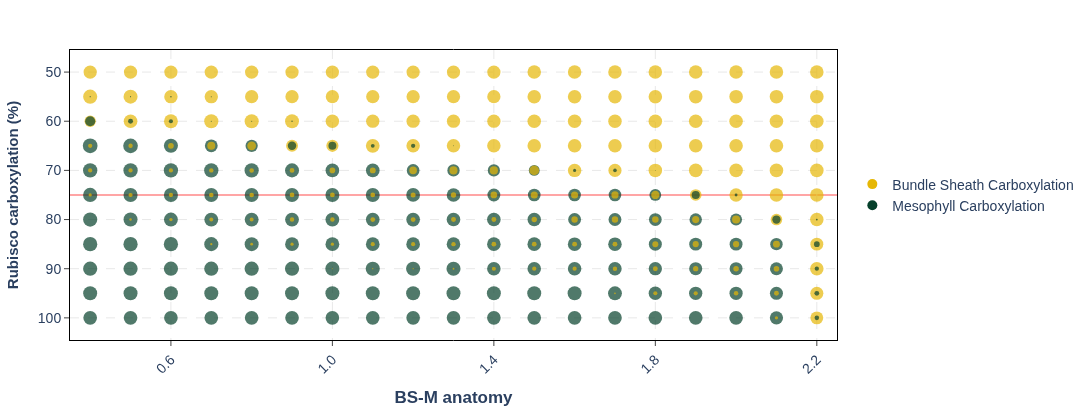

In [27]:
# Generate the bubble plot
plot_flux_solutions_bubbles_single_box(structured_C4, output_svg="../Images/Bubble_single.svg", CO2=20, PC_BS=1, NH3=1000)